# 02 - Results, evaluation and interpretation
**Primary analysis (fixed in advance):** models tuned with `TimeSeriesSplit(5)` CV on 2015-2017, selected on 2018,
refitted on 2015-2018 and scored **once** on 2019 (`src/train.py`, `src/evaluate.py`).
**Robustness analysis:** a rolling-origin evaluation over the 2017-2019 seasons at 1-3 day horizons (`src/robustness.py`).
It was added after the primary result, to test whether that result generalises, and it changes the conclusion.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
import config as C
pd.set_option("display.precision", 2)

In [2]:
sel = json.loads((C.METRICS / "model_selection.json").read_text())
summ = json.loads((C.METRICS / "summary.json").read_text())
best = sel["selected_model"]
print("Selected on validation:", best, sel["family_val_mae"])
pd.DataFrame({k: v["best_params"] | {"cv_mae": v["cv_mae"]} for k, v in sel["cv"].items()}).T

Selected on validation: RandomForest {'RandomForest': 20.601, 'HistGB': 20.665, 'Ridge': 22.971}


,alpha,cv_mae,max_depth,max_features,min_samples_leaf,n_estimators,l2_regularization,learning_rate,max_iter
Ridge/no_fires,100.0,31.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ridge/with_fires,100.0,31.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RandomForest/no_fires,NaN,29.90,10.0,0.5,3.0,300.0,NaN,NaN,NaN
RandomForest/with_fires,NaN,30.07,NaN,0.5,3.0,300.0,NaN,NaN,NaN
HistGB/no_fires,NaN,30.93,3.0,NaN,20.0,NaN,1.0,0.03,200.0
HistGB/with_fires,NaN,30.71,3.0,NaN,20.0,NaN,1.0,0.03,500.0


## Split and leakage controls
```
2015 ---- 2016 ---- 2017 | 2018 | 2019 | 2020 H1
   TRAIN (CV, 5 folds)    | VAL  | TEST | extra (COVID shift)
```
* The split is by **date predicted** (t+1), not random. Neighbouring days are almost identical, so a random split leaks.
* Imputation and scaling are inside sklearn Pipelines, fitted per CV fold.
* `tests/test_features.py` scrambles all data after a cut-off day and asserts that no feature on or before that day changes.

In [3]:
val = pd.read_csv(C.METRICS / "validation_metrics.csv")
val[["model", "variant", "overall_MAE", "fire_season_MAE"]]

,model,variant,overall_MAE,fire_season_MAE
0,Persistence,baseline,23.40,42.94
1,SeasonalMean,baseline,34.89,65.77
2,Ridge,no_fires,23.12,41.75
3,Ridge,with_fires,22.82,39.91
4,RandomForest,no_fires,20.60,35.49
5,RandomForest,with_fires,20.60,34.39
6,HistGB,no_fires,20.67,36.59
7,HistGB,with_fires,20.66,37.61


**Model selection.** The rule was fixed in advance: lowest *mean* validation MAE over the with- and without-fires
variants, so the choice does not favour either side of the fire comparison. Random Forest (20.60) narrowly beat HistGB
(20.67). The test-set ranking (below) turns out slightly different. We keep the pre-registered choice rather than
switching after seeing the test result.

## Test-year results (2019)

In [4]:
tm = pd.read_csv(C.METRICS / "test_metrics.csv")
tm.pivot_table(index=["model", "variant"], columns="scope", values=["MAE", "RMSE", "R2"]).round(2)

MAE                  R2                RMSE  \
scope                   fire_season overall fire_season overall fire_season   
model        variant                                                          
HistGB       no_fires         50.99   24.36        0.54    0.78       77.90   
             with_fires       47.30   23.43        0.56    0.79       76.31   
Persistence  baseline         54.45   27.95        0.46    0.71       84.08   
RandomForest no_fires         52.97   25.28        0.52    0.77       79.38   
             with_fires       50.57   25.30        0.57    0.78       74.85   
Ridge        no_fires         56.43   27.31        0.38    0.72       90.24   
             with_fires       57.80   27.22        0.38    0.72       90.45   
SeasonalMean baseline         97.17   43.61       -0.07    0.48      118.31   

                                 
scope                   overall  
model        variant             
HistGB       no_fires     39.97  
             with_fires   38.84  
Persistence  baseline     46.38  
RandomForest no_fires     40.72  
             with_fires   40.26  
Ridge        no_fires     45.15  
             with_fires   45.21  
SeasonalMean baseline     61.69

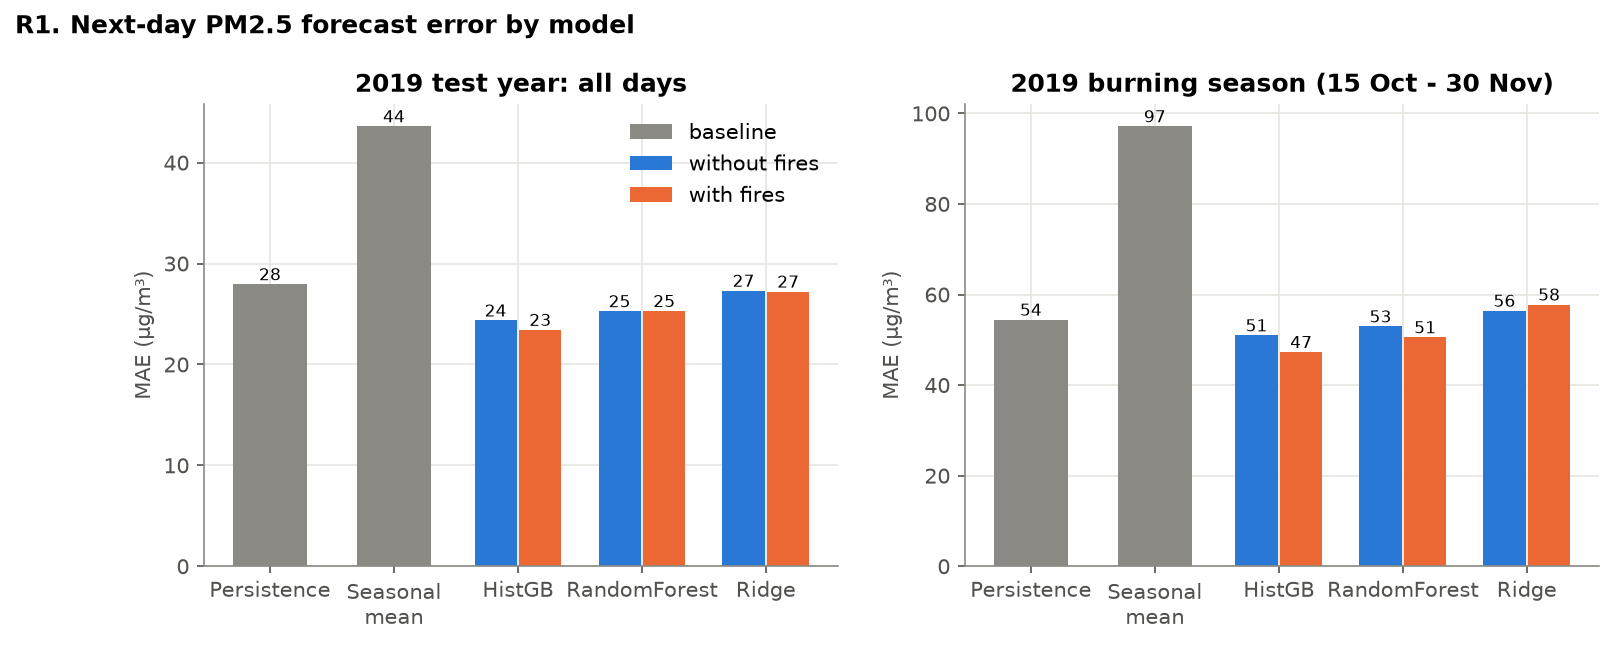

In [5]:
display(Image(C.FIGURES / "R1_model_comparison.png"))

**What this shows.**
* **G1 - beat persistence: met.** The selected Random Forest (with fires) has MAE 25.3 vs 28.0 for persistence overall
  (-9.5%), and 50.6 vs 54.5 in the burning season. HistGB is a little better still (23.4 / 47.3).
* The seasonal-mean baseline is far worse (43.6). Knowing the month is not enough; yesterday's air is the key information.
* Burning-season errors are about 2x the annual errors. This is the hardest period to forecast, and the one that matters most.
* Ridge does not beat persistence in the burning season: the relationships there are non-linear (thresholds, interactions).

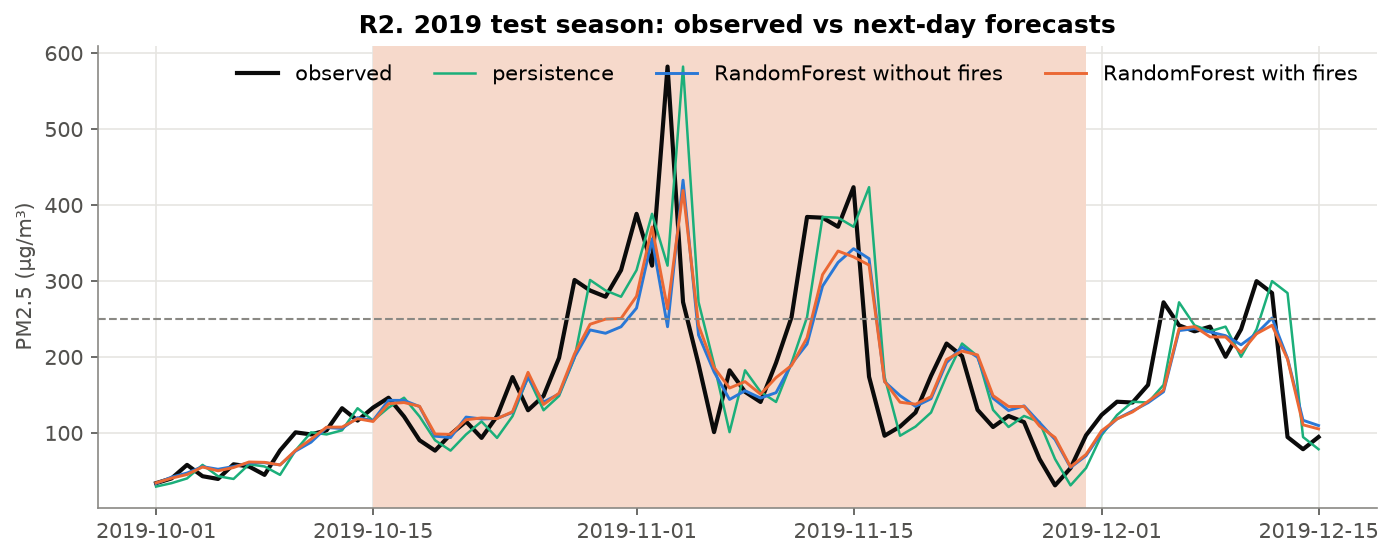

In [6]:
display(Image(C.FIGURES / "R2_test_season_forecast.png"))

**What this shows.** All forecasts follow the observed curve with roughly a **one-day lag**. They react to a spike
after it has started rather than anticipating it. The models are visibly smoother than persistence. They avoid
persistence's big overshoots after a spike collapses (e.g. 4-5 Nov), which is where most of their MAE gain comes from.
Sudden jumps such as 3 Nov (320 -> 582) are missed by every model.

## G2 - Do fire features help? (the core question)

In [7]:
rows = []
for m, r in summ["G2_fire_value"]["all_models"].items():
    for kind, d in r.items():
        rows.append({"model": m, "bootstrap": kind, "MAE no fires": d["mae_without"], "MAE with fires": d["mae_with"],
                     "gain": d["diff"], "gain %": 100 * d["rel_reduction"],
                     "95% CI low": d["ci95"][0], "95% CI high": d["ci95"][1], "P(gain<=0)": d["p_fires_not_helping"]})
pd.DataFrame(rows).round(3)

,model,bootstrap,MAE no fires,MAE with fires,gain,gain %,95% CI low,95% CI high,P(gain<=0)
0,Ridge,iid,56.43,57.80,-1.37,-2.43,-4.51,1.94,8.06e-01
1,Ridge,block7,56.43,57.80,-1.37,-2.43,-3.96,0.96,8.76e-01
2,RandomForest,iid,52.97,50.57,2.40,4.53,-0.05,5.05,2.70e-02
3,RandomForest,block7,52.97,50.57,2.40,4.53,0.55,5.32,4.00e-03
4,HistGB,iid,50.99,47.30,3.69,7.25,0.64,6.89,8.00e-03
5,HistGB,block7,50.99,47.30,3.69,7.25,-0.30,8.35,3.10e-02


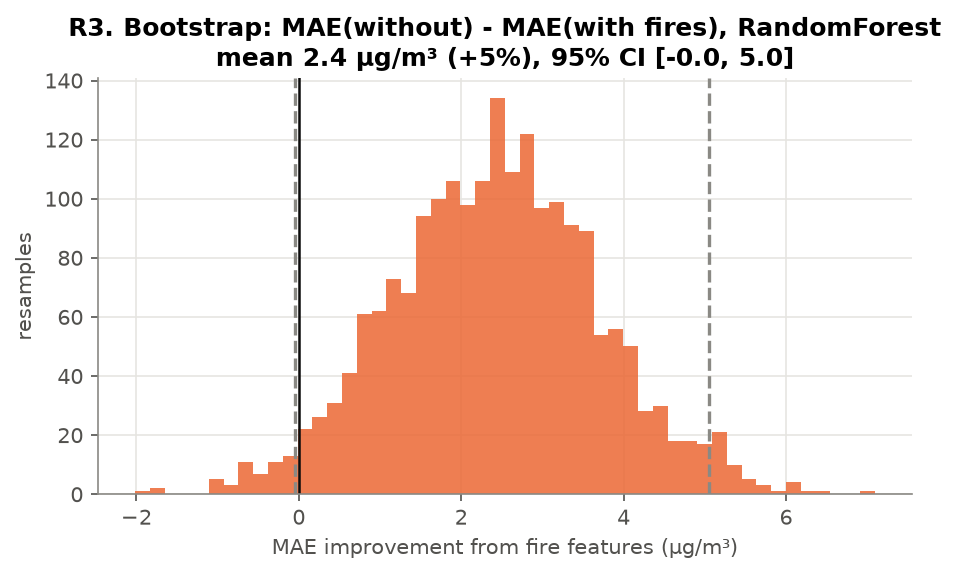

In [8]:
display(Image(C.FIGURES / "R3_bootstrap.png"))

**What this shows.**
* For the selected Random Forest, adding fire features lowers burning-season MAE by **2.4 ug/m3 (4.5%)**.
  The plain paired-bootstrap 95% CI is [-0.05, 5.05]: it just touches zero.
  **G2 (>= 10% with a CI excluding 0) is not met.**
* The direction is consistent for the tree models: HistGB gains 7.2% (CI [0.6, 6.9], excluding 0), and
  Random Forest is positive in 97% of resamples. Ridge gains nothing (-2.4%). The fire signal is non-linear and
  interacts with wind, which a linear model cannot use.
* The moving-block bootstrap (7-day blocks, which respects autocorrelation) does not change the picture: Random Forest's
  CI becomes [0.55, 5.32] (excludes 0), and HistGB's becomes [-0.30, 8.35] (just includes 0). With only 47 test days
  in one season, every interval is wide. Whichever bootstrap is used, the conclusion is the same: a positive gain of about
  5-7%, short of the 10% target.
* Over the whole year, fires make no difference (25.28 vs 25.30), as expected: there are no fires for most of the year.

**Interim reading:** on the 2019 season alone, fires appear to help the tree models by 5-7%. But the effect has the
opposite sign on the 2018 validation year for HistGB (37.6 with fires vs 36.6 without), and 47 days is a small
sample. So the next section tests the result across more seasons before drawing a conclusion.

## Robustness: three test seasons x three horizons (`src/robustness.py`)
**Rolling-origin evaluation.** Each burning season 2017, 2018 and 2019 is used as a test set in turn. The model is
re-tuned (TimeSeriesSplit CV) and trained **only on earlier years**. Pooling the three seasons gives 141 burning-season
test days instead of 47. The whole experiment is repeated for forecasts **1, 2 and 3 days ahead**: features still stop at
day *t*, and only the target moves further away. If fires carry real signal, it should appear consistently across
seasons, and more clearly at longer horizons, where today's PM2.5 is less informative.

In [9]:
rob = pd.read_csv(C.METRICS / "robustness_table.csv")
rob[["horizon", "model", "season MAE no fires", "season MAE with fires", "gain %", "iid CI low", "iid CI high",
     "gain % 2017", "gain % 2018", "gain % 2019", "folds improved (of 3)"]].round(2)

,horizon,model,season MAE no fires,season MAE with fires,gain %,iid CI low,iid CI high,gain % 2017,gain % 2018,gain % 2019,folds improved (of 3)
0,1,Ridge,49.48,49.13,0.71,-1.15,1.86,1.14,4.42,-2.43,2
1,1,RandomForest,44.86,45.72,-1.90,-3.03,1.15,-12.65,3.10,4.17,2
2,1,HistGB,45.54,45.83,-0.64,-2.56,2.00,-3.83,-2.79,4.06,1
3,2,Ridge,60.29,59.89,0.67,-1.56,2.42,4.81,-3.41,-0.28,1
4,2,RandomForest,59.86,59.73,0.22,-2.22,2.58,-2.28,-2.50,3.86,1
5,2,HistGB,59.75,61.87,-3.54,-5.34,0.87,-5.62,-18.56,6.61,1
6,3,Ridge,63.37,62.07,2.06,-1.17,3.60,4.64,-5.50,3.95,2
7,3,RandomForest,65.08,64.07,1.56,-1.78,3.85,-2.53,-5.03,8.12,1
8,3,HistGB,64.91,64.61,0.47,-2.96,3.31,0.85,-8.10,5.21,2


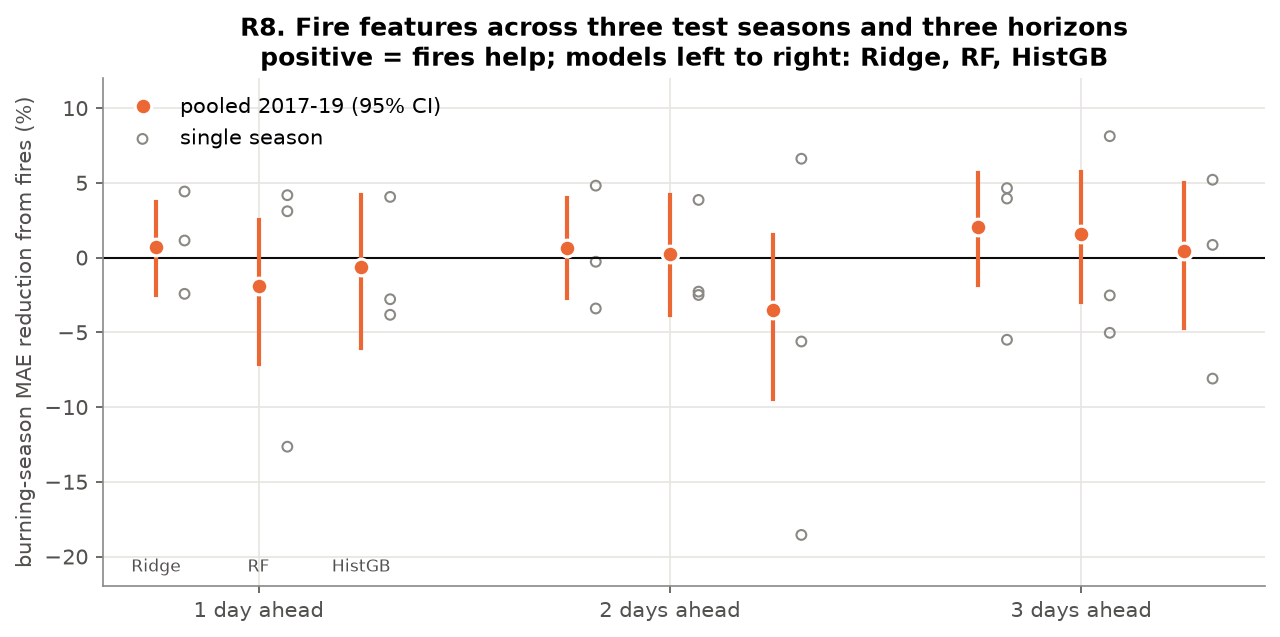

In [10]:
display(Image(C.FIGURES / "R8_robustness_fire_gain.png"))

**What this shows.**
* **The 2019 gain does not hold up.** In 2019, fires help every tree model at every horizon (+4% to +8%). In 2017 and
  2018 they often *hurt*: Random Forest at 1 day is -12.7% in 2017, and HistGB at 2 days is -18.6% in 2018. The
  single-season results range from -19% to +8%, while the pooled estimates sit near zero.
* **Pooled over 141 days, every model x horizon gain lies between -3.5% and +2.1%, and every 95% CI includes zero**
  (CIs in ug/m3 in the table; relative CIs span roughly -9% to +6%). The 2019 single-season estimate is within this
  season-to-season spread: it is what one lucky season looks like.
* **No hidden longer-horizon effect.** At 3 days ahead, where persistence is weakest, the gains are +0.5% to +2.1%,
  all with CIs including zero.

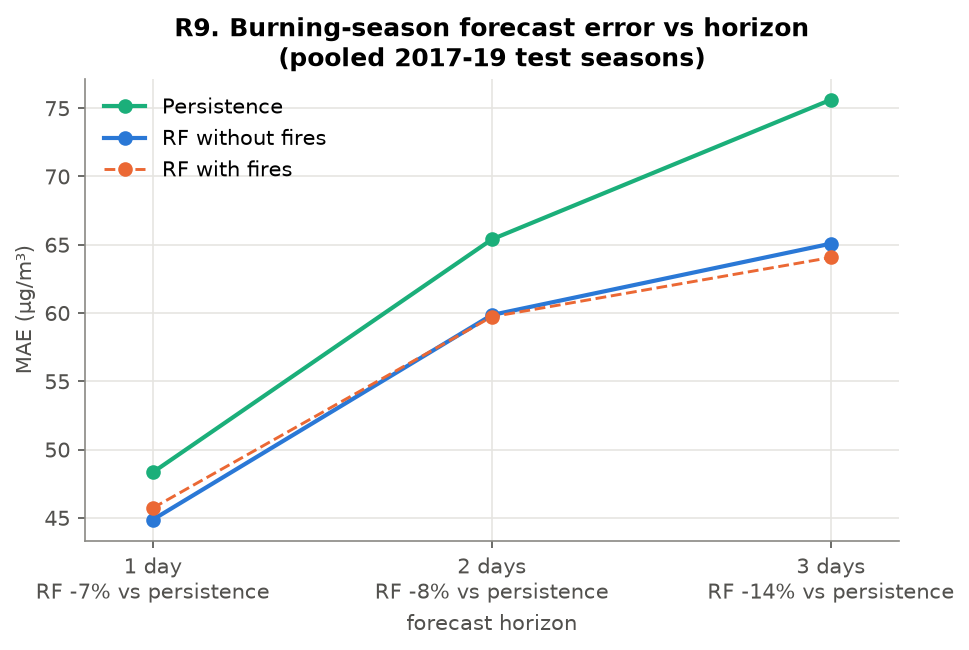

In [11]:
display(Image(C.FIGURES / "R9_error_vs_horizon.png"))

**What this shows.** The models' advantage over persistence **grows with the horizon**: -7% at 1 day, -8% at 2 days,
-14% at 3 days (Random Forest, burning season, pooled 2017-19). Weather and seasonal context matter more as yesterday's
value becomes less informative. The with-fires and without-fires lines lie on top of each other at every horizon.

## Answer to the research question
**Once Delhi's own pollution and weather are accounted for, satellite-detected farm fires in Punjab and Haryana add no
measurable skill to 1-3-day PM2.5 forecasts.** This holds across three burning seasons, three horizons and three model
types. The positive 2019 result was a single-season fluctuation; testing it on more seasons shows why one season is not
enough. This does **not** say fires do not pollute Delhi's air. Their smoke shows up in Delhi's PM2.5 and in the seasonal
weather pattern that the no-fires model already uses. For *forecasting*, the fire counts contain no information that
those variables do not already carry. The partial dependence (R6) suggests a plausible NW-wind transport pattern, but its
size is within the noise.

## G3 - Severe-day alerts

In [12]:
g3 = summ["G3_alerts"]["results"]
rows = []
for who, d in g3.items():
    for kind, a in d.items():
        rows.append({"model": who if who == "Persistence" else f"{best} {who}", "alert": kind,
                     "forecast thr": a["forecast_threshold"], "recall": a["recall"], "precision": a["precision"],
                     "TP": a["confusion_matrix [[TN, FP], [FN, TP]]"][1][1], "FN": a["confusion_matrix [[TN, FP], [FN, TP]]"][1][0],
                     "FP": a["confusion_matrix [[TN, FP], [FN, TP]]"][0][1]})
pd.DataFrame(rows).round(2)

,model,alert,forecast thr,recall,precision,TP,FN,FP
0,RandomForest no_fires,severe,250.0,0.38,0.72,13,21,5
1,RandomForest no_fires,very_poor_or_worse,120.0,0.86,0.84,92,15,18
2,RandomForest no_fires,severe_val_calibrated,220.0,0.74,0.64,25,9,14
3,RandomForest with_fires,severe,250.0,0.41,0.74,14,20,5
4,RandomForest with_fires,very_poor_or_worse,120.0,0.84,0.87,90,17,13
5,RandomForest with_fires,severe_val_calibrated,225.0,0.74,0.66,25,9,13
6,Persistence,severe,250.0,0.65,0.63,22,12,13
7,Persistence,very_poor_or_worse,120.0,0.84,0.84,90,17,17


**What this shows.**
* With the naive rule (alert if forecast > 250), recall for Severe days is only **0.41** (14 of 34) at precision 0.74,
  worse than persistence (0.65). **G3 is not met as originally specified.** The cause is regression to the mean: trained
  on a squared-error-like loss in log space, the model shrinks extreme forecasts (see R4: bias -70 on Severe days).
* A forecast is not a decision rule. Choosing the alert threshold on the **2018 validation year** to reach 70% recall
  gives a threshold of 225. On 2019 that gives **recall 0.74, precision 0.66** (25 of 34 caught, 13 false alarms),
  better than persistence on both. *This calibrated rule was added after the first test run and is reported as a secondary result.*
* For "Very Poor or worse" (> 120) alerts the model reaches recall 0.84 / precision 0.87.

In [13]:
pd.read_csv(C.METRICS / "category_confusion.csv", index_col=0)

,pred_Good,pred_Satisfactory,pred_Moderate,pred_Poor,pred_Very Poor,pred_Severe
actual_Good,9,14,2,0,0,0
actual_Satisfactory,3,57,27,8,2,0
actual_Moderate,0,13,43,21,1,0
actual_Poor,0,0,15,33,10,0
actual_Very Poor,0,0,1,16,51,5
actual_Severe,0,0,0,0,20,14


**Category confusion.** Almost all errors are off by one category (e.g. 20 Severe days predicted as Very Poor).
No Severe day is predicted below Very Poor, and only 2 Satisfactory days are predicted as Very Poor (none as Severe).

## Error analysis

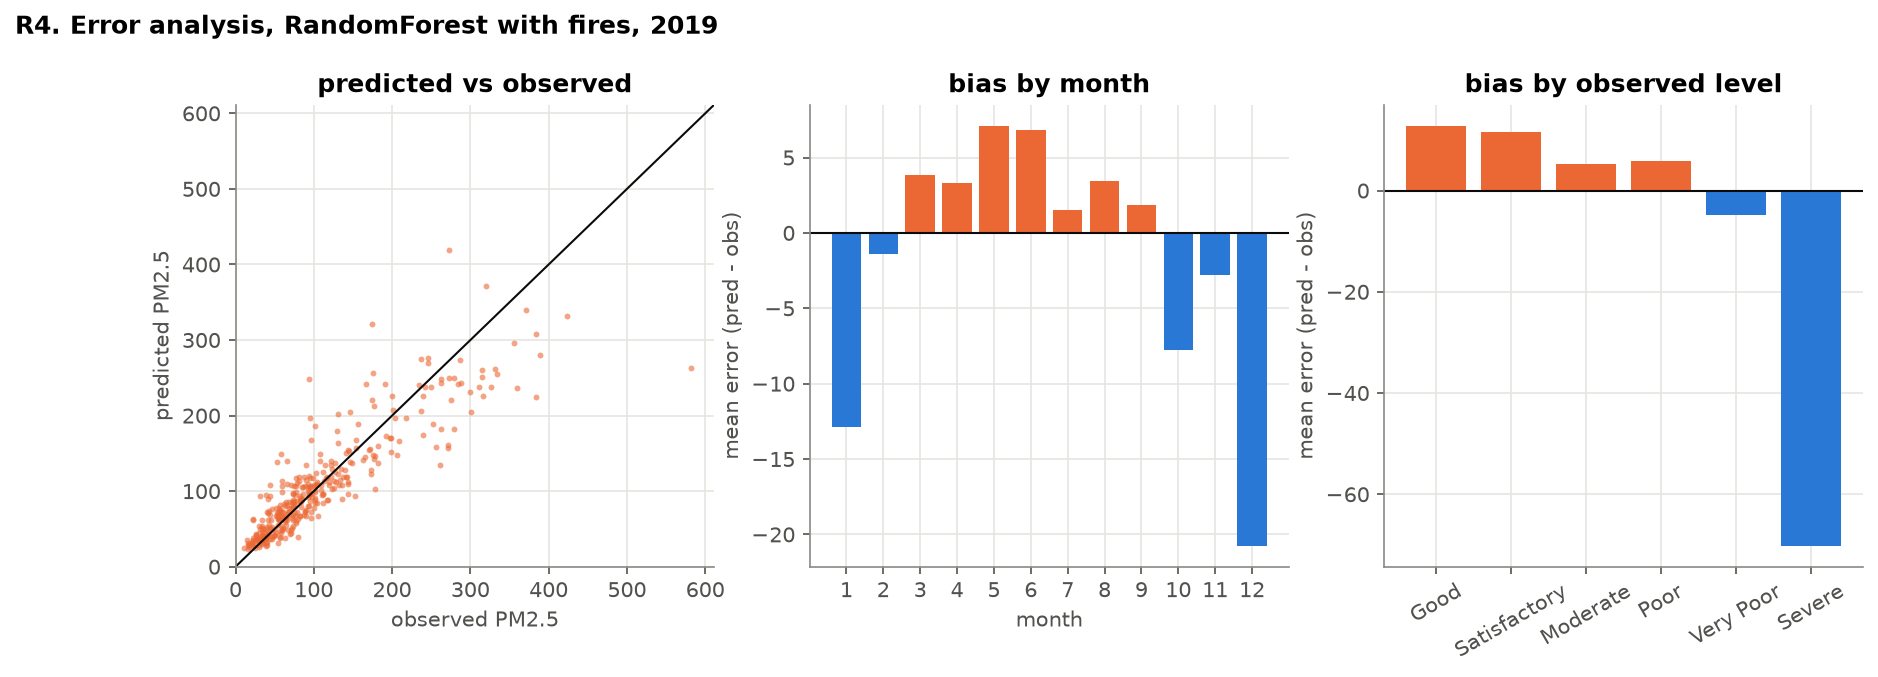

In [14]:
display(Image(C.FIGURES / "R4_error_analysis.png"))

In [15]:
display(pd.read_csv(C.METRICS / "error_by_level.csv"))
display(pd.read_csv(C.METRICS / "error_by_wind.csv"))
pd.read_csv(C.METRICS / "worst_days.csv")

,pm25_level,n,MAE,bias
0,Good,25,13.14,12.81
1,Satisfactory,97,15.70,11.53
2,Moderate,78,16.02,5.23
3,Poor,58,20.46,5.86
4,Very Poor,73,29.64,-4.86
5,Severe,34,81.80,-70.17


,nw_wind,n,MAE,bias
0,other wind,178,18.54,3.4
1,NW wind,187,31.73,-6.2


,target_date,pm25_next,RandomForest_with_fires,error,pm25_t,is_diwali_window,precip,wind_speed,nw_wind,fire_count_t
0,2019-11-03,582.3,263.4,-318.9,320.3,0,0.2,18.9,1,8
1,2019-11-12,384.3,225.2,-159.1,252.5,0,0.0,13.8,1,189
2,2019-01-14,94.4,247.9,153.4,272.4,0,0.0,13.2,1,8
3,2019-11-16,174.0,321.0,147.0,423.5,0,0.0,12.1,1,28
4,2019-11-04,272.3,419.2,146.9,582.3,0,0.0,13.1,1,26
5,2019-12-19,261.2,134.9,-126.3,144.0,0,0.0,14.0,1,0
6,2019-01-17,358.9,236.8,-122.1,272.0,0,0.0,9.4,0,0
7,2019-12-05,272.0,156.5,-115.5,163.2,0,0.0,9.3,1,35
8,2019-01-16,272.0,161.2,-110.7,134.6,0,0.0,17.1,1,1
9,2019-11-01,388.4,280.0,-108.4,314.3,0,0.0,12.7,1,731


**What this shows.**
* **Systematic shrinkage:** clean days are over-predicted (+12) and Severe days under-predicted (-70). Errors grow with the level.
* **By month:** the largest negative bias is in Dec and Jan (winter inversions, no fires). The model under-predicts winter
  smog that fires cannot explain.
* **By wind:** MAE is 31.7 on NW-wind days vs 18.5 otherwise, because NW days are mostly in the polluted season.
* **Worst days:** all 10 of the 10 worst errors are in Nov-Jan. The worst (3 Nov 2019: 582 observed vs 263 predicted) came during the
  peak of the 2019 episode (a public-health emergency was declared on 1 Nov). Fire detections on 2-3 Nov fell to 8 and 26,
  then jumped to 1,886 on 4 Nov. Thick smoke and haze probably hid the fires from the satellite exactly when they mattered
  most, a concrete example of the detection limitation. Several large *over*-predictions (4 Nov, 16 Nov, 14 Jan) are
  sudden clean-ups the day after a peak, which the persistence-driven models cannot anticipate. None of the 10 is a
  Diwali day: the Diwali flag works.

## Interpretation

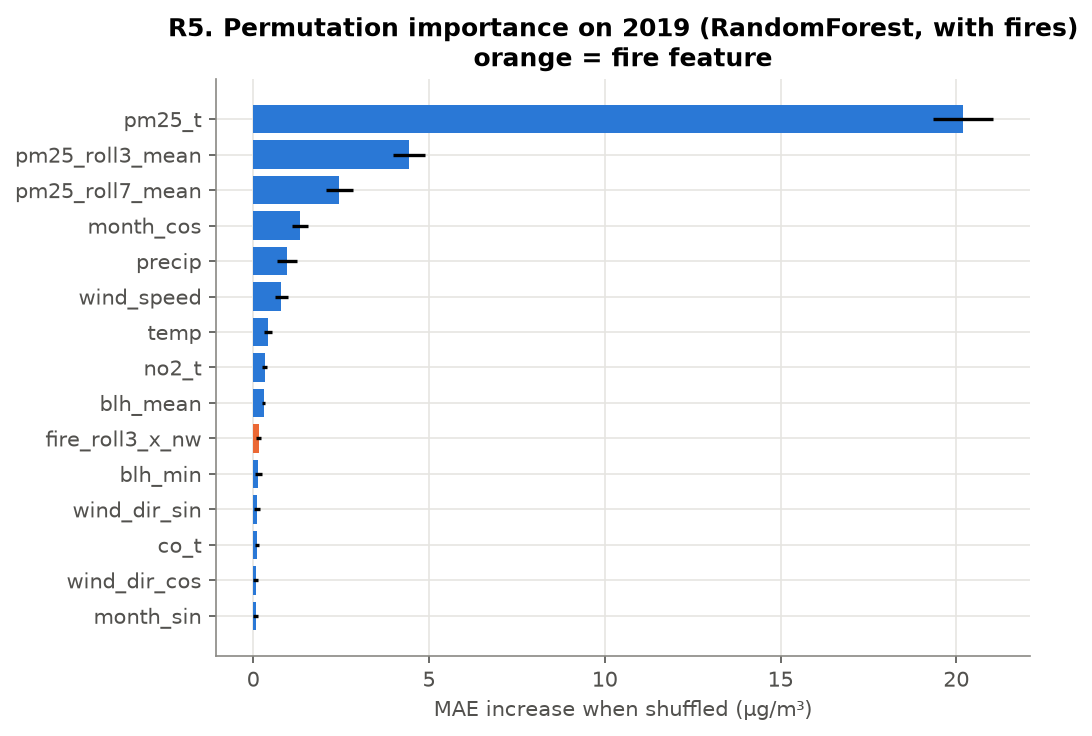

In [16]:
display(Image(C.FIGURES / "R5_permutation_importance.png"))

In [17]:
print("Shuffling ALL fire features together (MAE increase, ug/m3):", summ["fire_group_permutation"])

Shuffling ALL fire features together (MAE increase, ug/m3): {'fire_group_all_test': {'mae_increase_mean': 0.6632210711471732, 'mae_increase_std': 0.2202496362730497}, 'fire_group_fire_season': {'mae_increase_mean': 3.182540386904102, 'mae_increase_std': 0.8941653651989365}}


**Permutation importance (test 2019).** Today's PM2.5 dominates (+20 ug/m3 MAE when shuffled), followed by the 3- and
7-day means, season, rain and wind. Each fire feature on its own looks unimportant, because the ten fire features are
correlated and stand in for each other. Shuffling the **whole fire group** together raises burning-season MAE by
**3.2 ug/m3**, consistent with the ablation gain above (2.4).

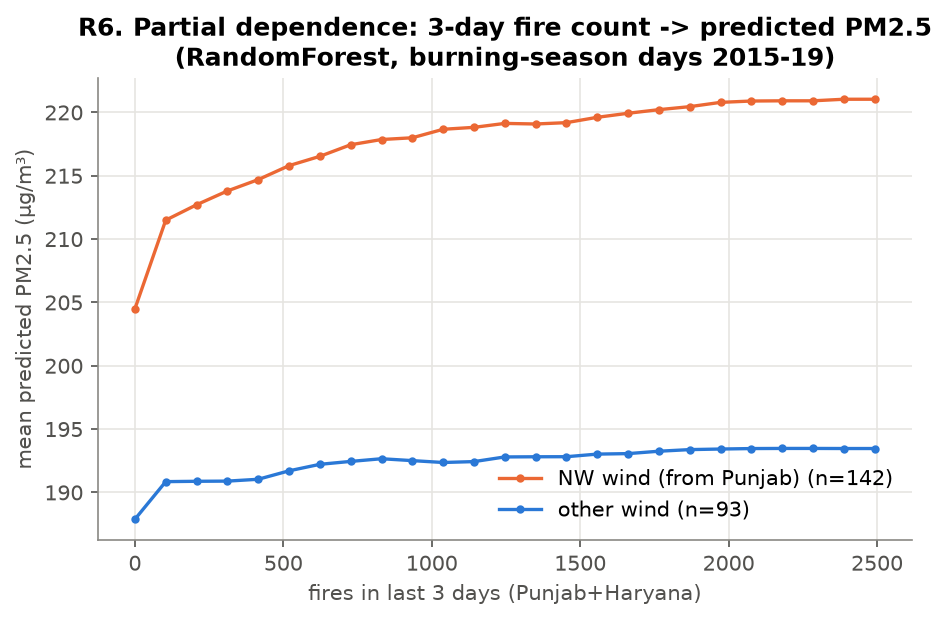

In [18]:
display(Image(C.FIGURES / "R6_partial_dependence.png"))

**Partial dependence.** Predicted PM2.5 rises with recent fire activity, steeply for the first few hundred fires and
then levelling off. The rise is larger with NW wind (about +17 ug/m3 from 0 to 2,500 fires) than with other winds
(about +6). This is the expected physical pattern: smoke is transported when the wind blows from Punjab. It is still
modest next to the effect of persistence.

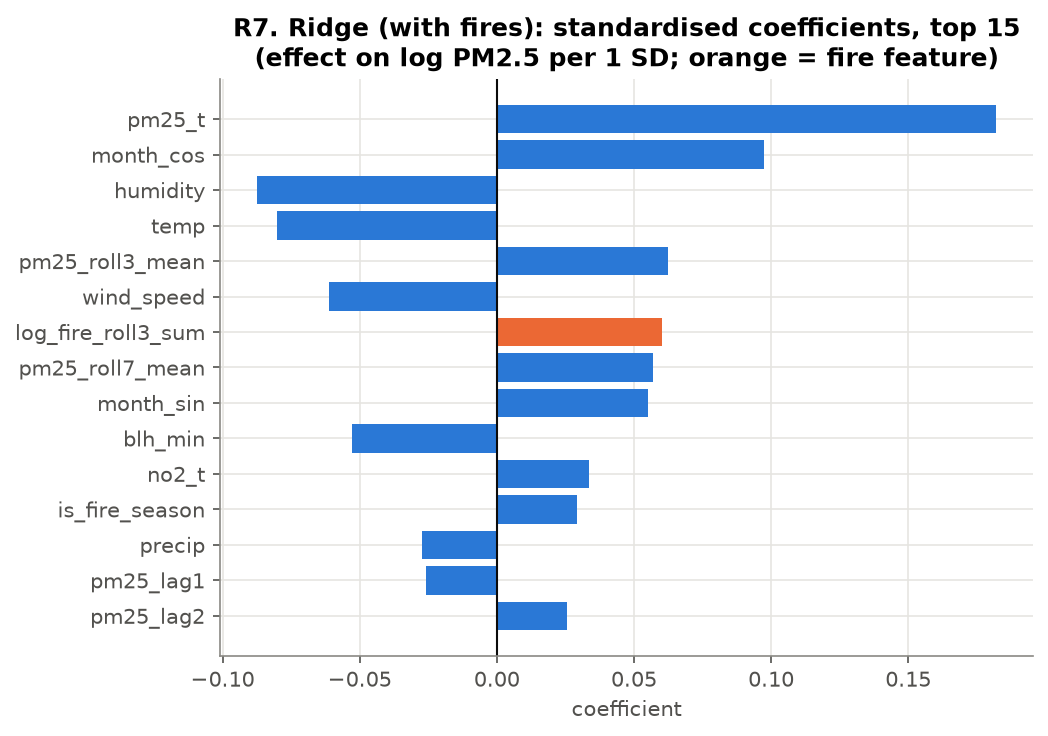

In [19]:
display(Image(C.FIGURES / "R7_ridge_coefficients.png"))

**Ridge coefficients** (standardised, log scale): today's PM2.5, winter month, humidity, temperature and wind speed
come first. `log_fire_roll3_sum` is the 7th-largest coefficient by magnitude, so the linear model does give fires a role, but it
does not improve its burning-season error.

## Stress test: 2020 H1 (COVID lockdown, no burning season)

In [20]:
pd.read_csv(C.METRICS / "extra2020_metrics.csv")[["model", "variant", "MAE", "R2"]].round(2)

,model,variant,MAE,R2
0,Persistence,baseline,19.75,0.72
1,SeasonalMean,baseline,47.47,-0.01
2,Ridge,no_fires,21.72,0.74
3,Ridge,with_fires,21.38,0.75
4,RandomForest,no_fires,17.34,0.80
5,RandomForest,with_fires,17.25,0.80
6,HistGB,no_fires,17.09,0.80
7,HistGB,with_fires,17.05,0.80


The tree models still beat persistence (17.1-17.3 vs 19.7) through the lockdown distribution shift, and with/without
fires are identical, as they should be with no fires. The models are not just memorising pre-COVID levels.

## Limitations and bias
* **Predictive, not causal.** Fire features not improving forecasts does not mean fires do not pollute; and it does not measure the share of Delhi's
  PM2.5 caused by fires (that needs chemical-transport or source-apportionment models).
* **Satellite detection gaps:** MODIS passes about 10:30 and 13:30 local time; burning has shifted to evenings, and
  smoke/cloud hide fires. Counts are a proxy for burning.
* **Region:** a bounding box, not state polygons; it includes a sliver of western UP.
* **Spatial averaging:** the city-average PM2.5 hides large differences between stations; weather is one ERA5 grid point.
* **Small evaluation sample:** a single test season has only 47 burning-season days. The rolling-origin analysis
  raises this to 141, but that is still only three seasons, and season-to-season variation is large.
* **Observed, not forecast, weather:** we used day-*t* weather. Real forecasts would use NWP forecasts for t+1, which would likely help all models.
* **Post-hoc addition:** the calibrated alert threshold was added after the first test evaluation (it is chosen on validation data only).

## Next steps
VIIRS 375 m fires (more sensitive, catches small/evening fires); state polygons; NWP forecast weather for day t+1;
2021-2025 CPCB data for more fire seasons (the most direct way to tighten the CIs); HYSPLIT back-trajectories to weight fires by whether their air actually reaches Delhi; quantile loss for better extremes.